# DETR: object detection with a Transformer

[DETR](https://arxiv.org/abs/2005.12872) (*DEtection TRansformer*, Carion et al. 2020, Meta) changed how object
detectors are built. Earlier detectors (Faster R-CNN, YOLO — see the YOLO lecture in module 2) predict thousands of
boxes around predefined *anchor* positions and remove the duplicates afterwards with *non-maximum suppression*.
DETR instead predicts a **set** of exactly 100 boxes directly: a CNN extracts image features, a Transformer encoder
mixes them, and a Transformer decoder turns 100 learned **object queries** into 100 predictions — a class (or
"no object") and a box each.

During training each ground-truth object is matched with exactly one prediction (the *Hungarian* algorithm finds the
best one-to-one assignment), so the model learns to produce each object once: no anchors and no duplicate removal.
Most later detectors build on this idea — including the detector inside SAM 3 (see the SAM3 notebooks).

The released models (on Hugging Face) are trained on **COCO** (80 kinds of objects):

| model | backbone | parameters | task |
|---|---|---|---|
| `facebook/detr-resnet-50` | ResNet-50 | 41 M | boxes |
| `facebook/detr-resnet-101` | ResNet-101 | 60 M | boxes |
| `facebook/detr-resnet-50-panoptic` | ResNet-50 | 43 M | boxes + masks for objects and background ("panoptic") |

DETR is small enough to run on a CPU instance (a few seconds per image); a GPU makes it ~20 times faster.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from huggingface_hub.utils import logging as hub_logging
from PIL import Image
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
hub_logging.set_verbosity_error()  # no warning about downloading without a Hugging Face login (not needed here)
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
# The figures are mostly photos: JPEG at retina resolution keeps the notebook small.
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]


def load_coco(image_id: int) -> Image.Image:
    url = f"https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/{image_id:012d}.jpg"
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")


def show(ax, image, boxes, labels, scores=None, title=""):
    """Image with boxes (N, 4) in xyxy pixels; one color per label name."""
    ax.imshow(image)
    names = sorted(set(labels))
    for i, (box, label) in enumerate(zip(np.asarray(boxes), labels)):
        x0, y0, x1, y1 = box
        color = COLORS[names.index(label) % len(COLORS)]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, lw=2))
        text = label if scores is None else f"{label} {float(scores[i]):.2f}"
        ax.text(x0, y0 - 2, text, color="white", fontsize=8, bbox=dict(facecolor=color, edgecolor="none", pad=1))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

## 1. Detecting objects

The processor resizes the image (shorter side 800 px, longer side at most 1333 px) and normalizes it.

In [2]:
from transformers import AutoImageProcessor, DetrForObjectDetection

processor = AutoImageProcessor.from_pretrained("facebook/detr-resnet-50")
model = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50").to(device).eval()
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters")

cats = load_coco(39769)
inputs = processor(images=cats, return_tensors="pt").to(device)
print("image:", cats.size, " ", {name: tuple(value.shape) for name, value in inputs.items()})

with torch.no_grad():
    outputs = model(**inputs)
print({name: tuple(outputs[name].shape) for name in ["logits", "pred_boxes"]})

42 M parameters
image: (640, 480)   {'pixel_mask': (1, 800, 1066), 'pixel_values': (1, 3, 800, 1066)}


{'logits': (1, 100, 92), 'pred_boxes': (1, 100, 4)}


For each of the **100 queries**, the model returns:

- `logits`: scores for 92 classes — the COCO category ids 0–90 and, in the last position, **"no object"**. COCO's
  numbering has gaps (id 0, and 10 categories such as "hat" and "shoe" that were planned but never annotated), so
  the model has learned 80 real classes;
- `pred_boxes`: a box $(c_x, c_y, w, h)$ as fractions of the image size.

`post_process_object_detection` applies a softmax, takes the most likely real class of each query, keeps the queries
whose probability is above `threshold`, and converts the boxes to pixels $(x_0, y_0, x_1, y_1)$:

    label  score box (x0, y0, x1, y1)
0  remote  0.998   [40, 71, 176, 118]
1  remote  0.996  [333, 73, 368, 188]
2   couch  0.995     [0, 1, 640, 474]
3     cat  0.999   [13, 52, 314, 471]
4     cat  0.999  [345, 24, 640, 369]


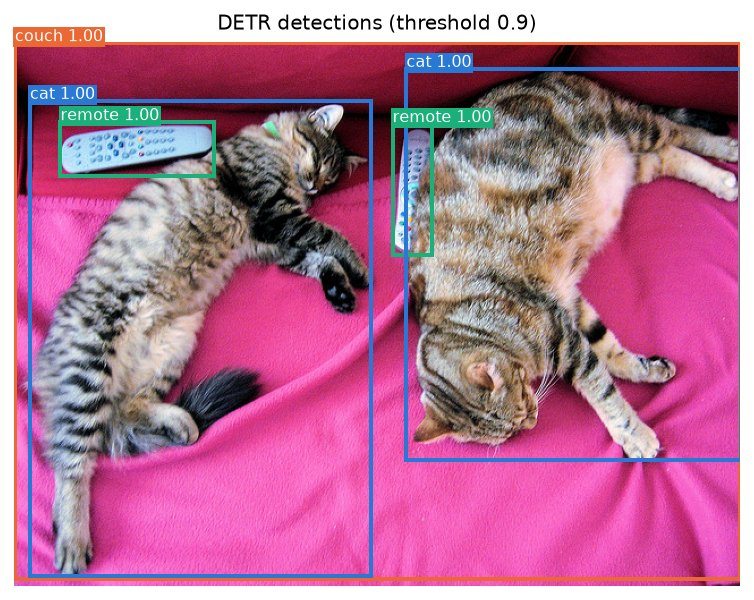

In [3]:
results = processor.post_process_object_detection(outputs, threshold=0.9, target_sizes=[cats.size[::-1]])[0]
labels = [model.config.id2label[i] for i in results["labels"].tolist()]
print(pd.DataFrame({"label": labels, "score": results["scores"].cpu().numpy().round(3),
                    "box (x0, y0, x1, y1)": results["boxes"].cpu().numpy().round().astype(int).tolist()}))

fig, ax = plt.subplots(figsize=(6.5, 5))
show(ax, cats, results["boxes"].cpu(), labels, results["scores"].cpu(), title="DETR detections (threshold 0.9)")
plt.show()

### "No object"

Every query predicts *something*, but most of them predict "no object". The probability of "no object" for each of
the 100 queries, sorted: only a handful of queries found something in this image.

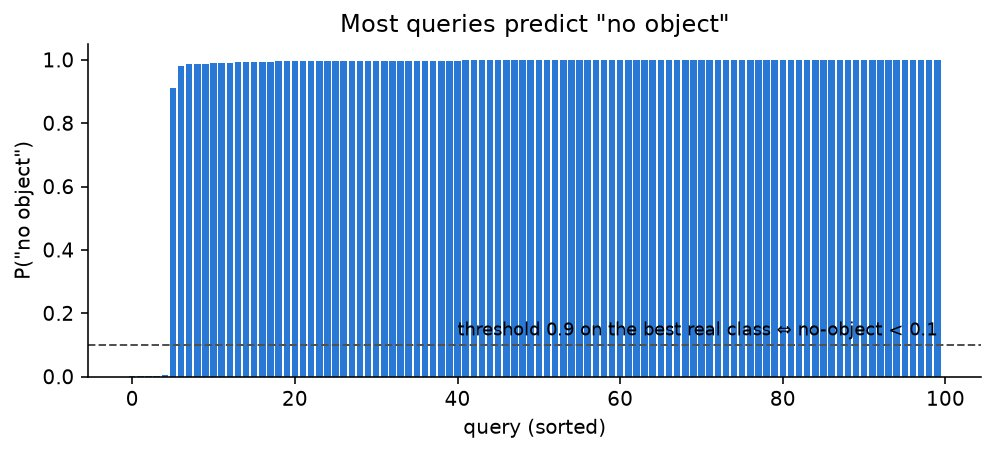

queries with P(no object) < 0.1: 5


In [4]:
probabilities = outputs.logits.softmax(dim=-1)[0].cpu()
no_object = probabilities[:, -1].sort().values

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(100), no_object, color=COLORS[0], width=0.8)
ax.axhline(0.1, color="#52514e", ls="--", lw=1)
ax.text(99, 0.13, "threshold 0.9 on the best real class ⇔ no-object < 0.1", ha="right", fontsize=9)
ax.set(xlabel="query (sorted)", ylabel='P("no object")', title='Most queries predict "no object"')
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print("queries with P(no object) < 0.1:", int((no_object < 0.1).sum()))

## 2. More images, and the pipeline

`pipeline("object-detection")` wraps the same steps — loading, processing, the model, post-processing — in one call:

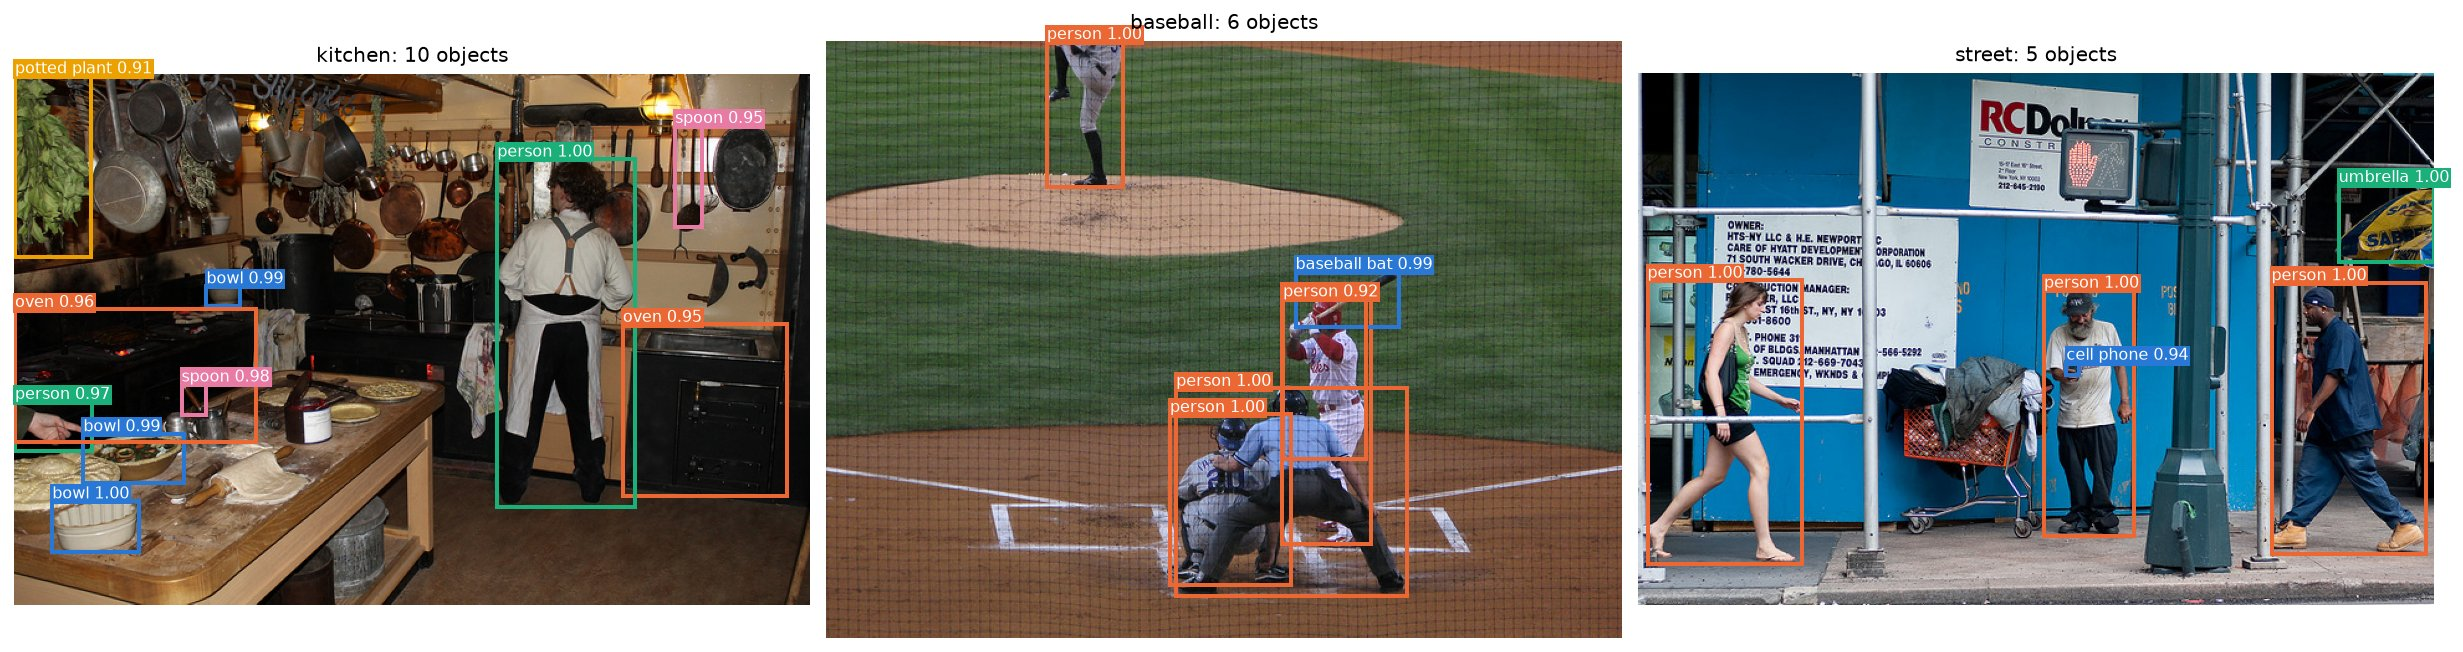

[{'score': 0.9254856109619141,
  'label': 'person',
  'box': {'xmin': 366, 'ymin': 207, 'xmax': 438, 'ymax': 404}},
 {'score': 0.9966599941253662,
  'label': 'person',
  'box': {'xmin': 276, 'ymin': 300, 'xmax': 373, 'ymax': 437}}]

In [5]:
from transformers import pipeline

detector = pipeline("object-detection", model="facebook/detr-resnet-50", device=device, threshold=0.9)
images = {"kitchen": load_coco(397133), "baseball": load_coco(2153), "street": load_coco(252219)}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for ax, (name, image) in zip(axes, images.items()):
    detections = detector(image)
    boxes = [[d["box"][k] for k in ("xmin", "ymin", "xmax", "ymax")] for d in detections]
    show(ax, image, boxes, [d["label"] for d in detections], [d["score"] for d in detections],
         title=f"{name}: {len(detections)} objects")
plt.show()
detector(images["baseball"])[:2]

## 3. A closed vocabulary

DETR can only name the 80 COCO categories it was trained on. The herd from the SAM3 notebook contains goats; COCO has
no "goat", so DETR (like the COCO annotators) calls them **sheep** — or, the dark ones, **cows**. SAM 3, which reads a text prompt, has no such
limit.

80 classes: airplane, apple, backpack, banana, baseball bat, baseball glove, bear, bed, bench, bicycle, bird, boat, book, bottle, bowl, broccoli, bus, cake, car, carrot, cat, cell phone, chair, clock, couch, cow, cup, dining table, dog, donut, elephant, fire hydrant, fork, frisbee, giraffe, hair drier, handbag, horse, hot dog, keyboard, kite, knife, laptop, microwave, motorcycle, mouse, orange, oven, parking meter, person, pizza, potted plant, refrigerator, remote, sandwich, scissors, sheep, sink, skateboard, skis, snowboard, spoon, sports ball, stop sign, suitcase, surfboard, teddy bear, tennis racket, tie, toaster, toilet, toothbrush, traffic light, train, truck, tv, umbrella, vase, wine glass, zebra


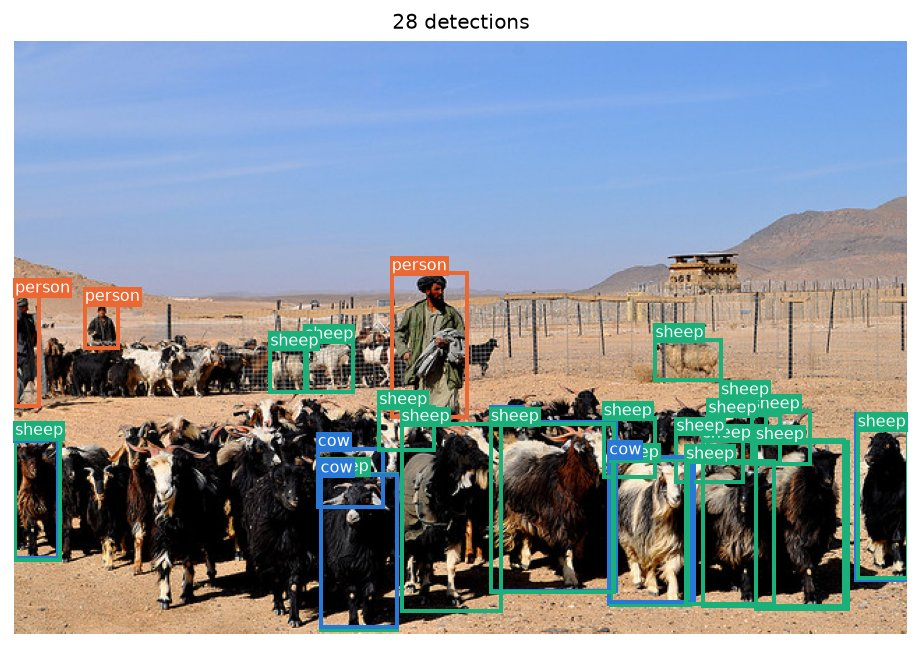

sheep     18
cow        7
person     3
Name: count, dtype: int64

In [6]:
never_annotated = {"blender", "desk", "door", "eye glasses", "hat", "mirror", "plate", "shoe", "street sign", "window"}
coco_classes = sorted(name for name in model.config.id2label.values() if name != "N/A" and name not in never_annotated)
print(len(coco_classes), "classes:", ", ".join(coco_classes))

goats = load_coco(181666)
detections = detector(goats, threshold=0.5)  # a lower threshold than above, to see more of the herd
fig, ax = plt.subplots(figsize=(8, 5.5))
show(ax, goats, [[d["box"][k] for k in ("xmin", "ymin", "xmax", "ymax")] for d in detections],
     [d["label"] for d in detections], title=f"{len(detections)} detections")
plt.show()
pd.Series([d["label"] for d in detections]).value_counts()

## 4. Batches of different sizes

Images of different sizes are padded to the size of the largest one in the batch. `pixel_mask` marks the real pixels
(1) and the padding (0); the model ignores the padding in its attention.

image sizes: [(640, 480), (375, 500), (444, 640)]  batch: {'pixel_mask': (3, 1153, 1066), 'pixel_values': (3, 3, 1153, 1066)}


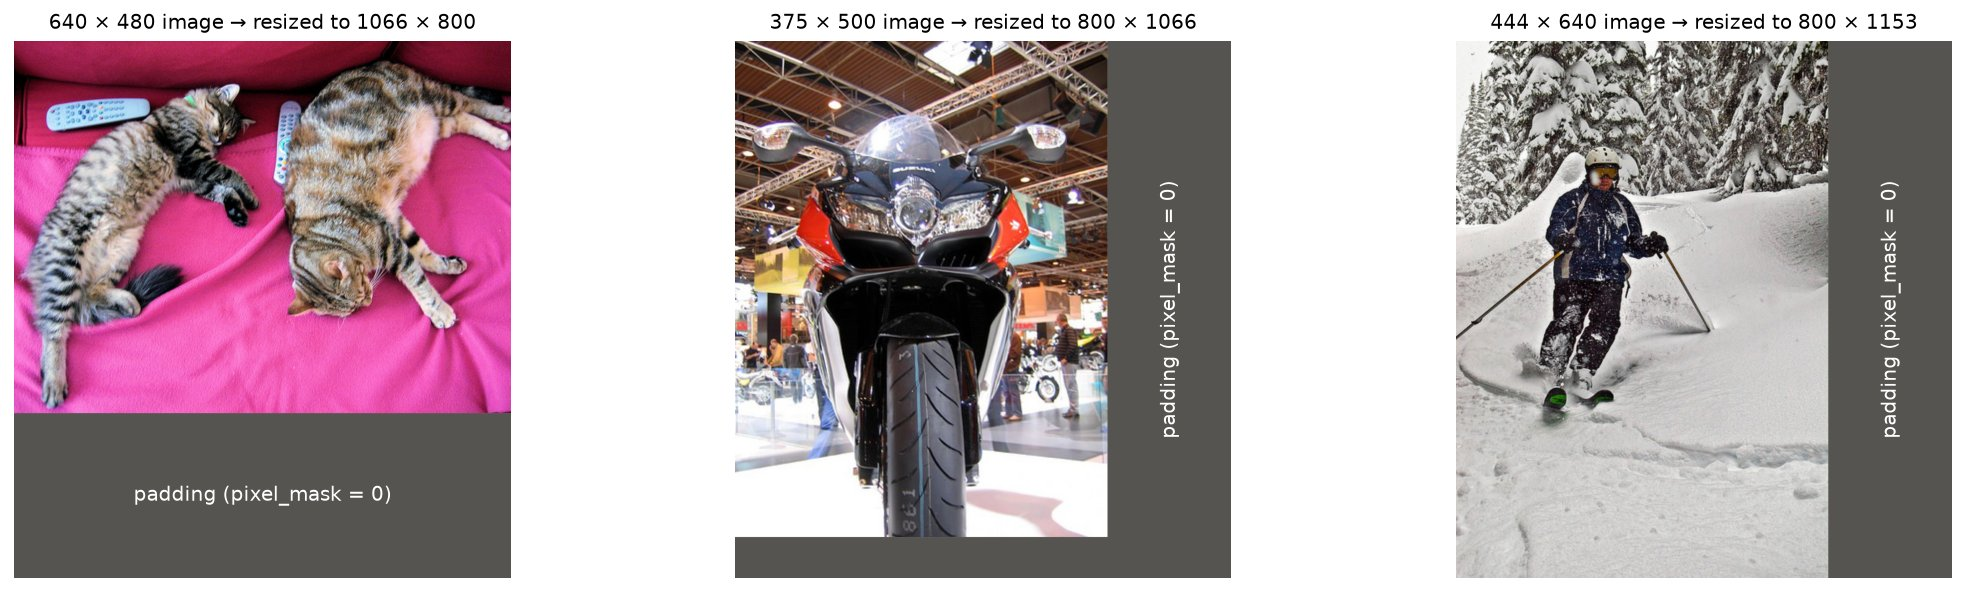

objects per image: [5, 10, 2]


In [7]:
batch = [cats, load_coco(480985), load_coco(5529)]            # a landscape and two portrait images
inputs = processor(images=batch, return_tensors="pt").to(device)
print("image sizes:", [image.size for image in batch], " batch:", {name: tuple(value.shape) for name, value in inputs.items()})

mean = torch.tensor(processor.image_mean).view(3, 1, 1)
std = torch.tensor(processor.image_std).view(3, 1, 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, pixels, mask, image in zip(axes, inputs["pixel_values"].cpu(), inputs["pixel_mask"].cpu(), batch):
    picture = (pixels * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()  # undo the normalization
    ax.imshow(picture)
    padding = np.zeros((*mask.shape, 4))
    padding[mask.numpy() == 0] = (0.32, 0.32, 0.31, 0.9)                 # dark gray where pixel_mask is 0
    ax.imshow(padding)
    height, width = int(mask.any(dim=1).sum()), int(mask.any(dim=0).sum())
    right, bottom = mask.shape[1] - width, mask.shape[0] - height              # padding added on each side
    if right >= bottom and right > 0:
        ax.text(width + right / 2, mask.shape[0] / 2, "padding (pixel_mask = 0)", color="white", ha="center",
                va="center", rotation=90, fontsize=10)
    elif bottom > 0:
        ax.text(mask.shape[1] / 2, height + bottom / 2, "padding (pixel_mask = 0)", color="white", ha="center",
                va="center", fontsize=10)
    ax.set_title(f"{image.size[0]} × {image.size[1]} image → resized to {width} × {height}", fontsize=10)
    ax.axis("off")
plt.show()

with torch.no_grad():
    outputs = model(**inputs)
batch_results = processor.post_process_object_detection(outputs, threshold=0.9, target_sizes=[im.size[::-1] for im in batch])
print("objects per image:", [len(r["scores"]) for r in batch_results])

## 5. Panoptic segmentation

`facebook/detr-resnet-50-panoptic` adds a mask head. *Panoptic* segmentation labels **every pixel**: countable
objects ("things": cats, remotes) get one segment each, and background regions ("stuff": wall, floor, sky) one segment
per kind. `post_process_panoptic_segmentation` returns a segment id per pixel and the label of each segment. The model's
configuration only names the things; the 53 "stuff" categories of COCO panoptic (ids 92–200, from
[panopticapi](https://github.com/cocodataset/panopticapi/blob/master/panoptic_coco_categories.json)) are listed here.

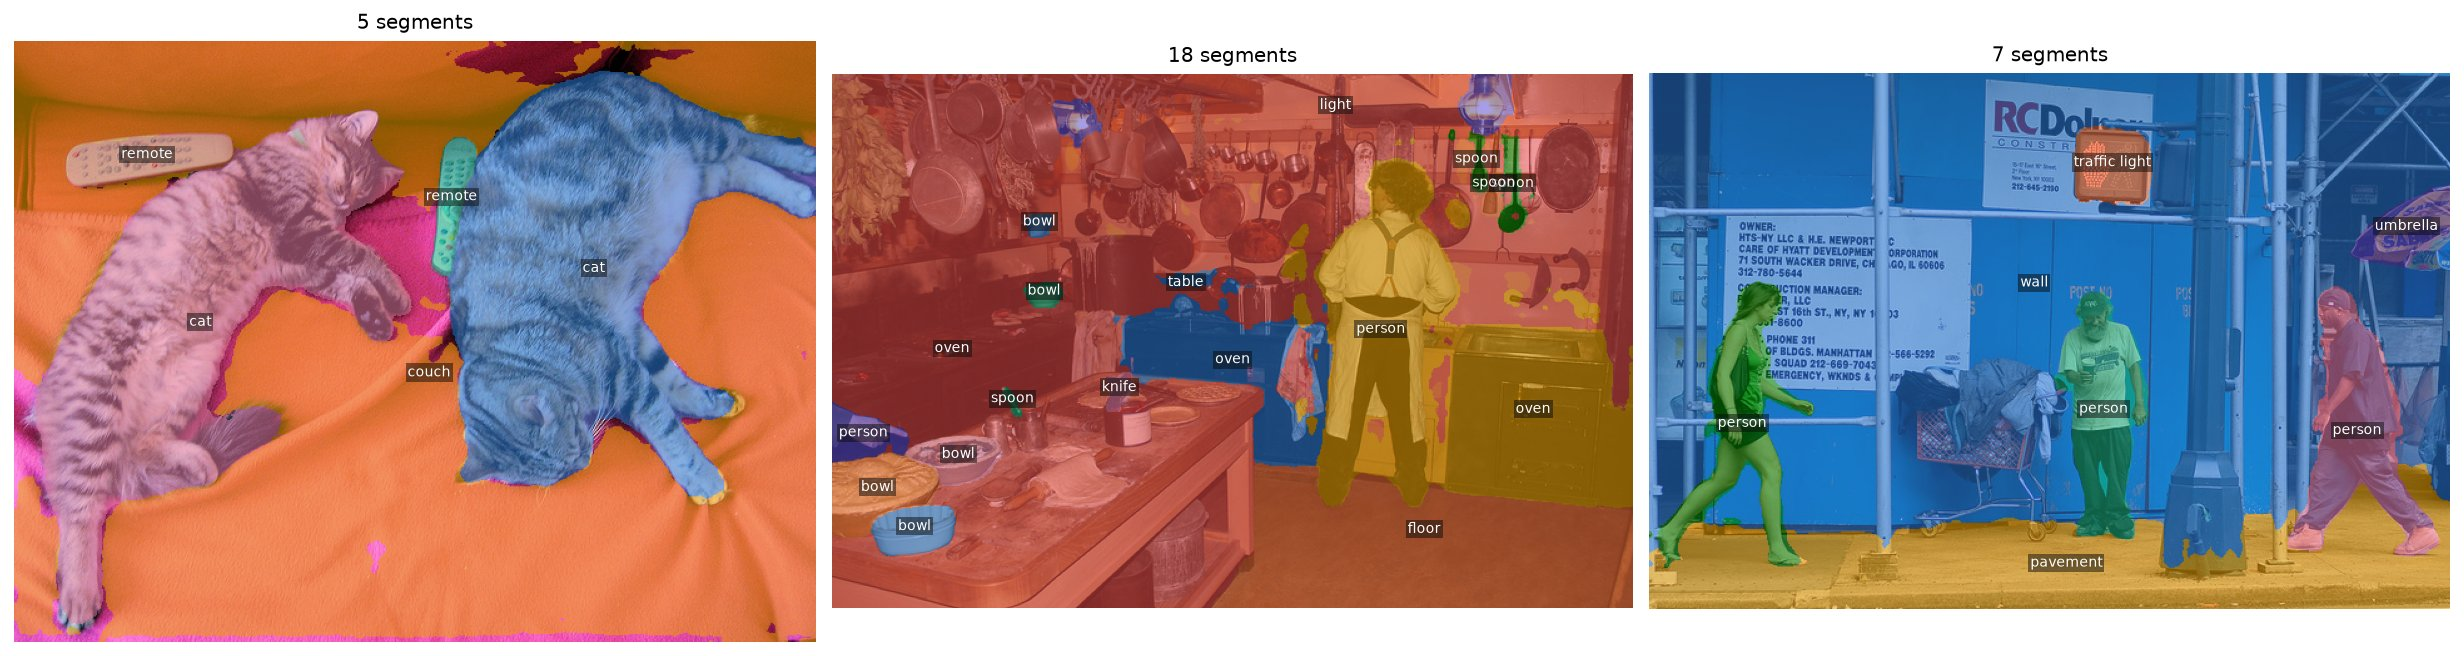

In [8]:
from transformers import DetrForSegmentation

STUFF = {92: "banner", 93: "blanket", 95: "bridge", 100: "cardboard", 107: "counter", 109: "curtain", 112: "door",
         118: "floor (wood)", 119: "flower", 122: "fruit", 125: "gravel", 128: "house", 130: "light", 133: "mirror",
         138: "net", 141: "pillow", 144: "platform", 145: "playing field", 147: "railroad", 148: "river", 149: "road",
         151: "roof", 154: "sand", 155: "sea", 156: "shelf", 159: "snow", 161: "stairs", 166: "tent", 168: "towel",
         171: "wall (brick)", 175: "wall (stone)", 176: "wall (tile)", 177: "wall (wood)", 178: "water", 180: "blind",
         181: "window", 184: "tree", 185: "fence", 186: "ceiling", 187: "sky", 188: "cabinet", 189: "table",
         190: "floor", 191: "pavement", 192: "mountain", 193: "grass", 194: "dirt", 195: "paper", 196: "food",
         197: "building", 198: "rock", 199: "wall", 200: "rug"}

panoptic_processor = AutoImageProcessor.from_pretrained("facebook/detr-resnet-50-panoptic")
panoptic = DetrForSegmentation.from_pretrained("facebook/detr-resnet-50-panoptic").to(device).eval()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for ax, image in zip(axes, [cats, images["kitchen"], images["street"]]):
    with torch.no_grad():
        segmentation_outputs = panoptic(**panoptic_processor(images=image, return_tensors="pt").to(device))
    result = panoptic_processor.post_process_panoptic_segmentation(
        segmentation_outputs, threshold=0.85, target_sizes=[image.size[::-1]])[0]
    segments = result["segmentation"].cpu().numpy()
    overlay = np.zeros((*segments.shape, 4))
    ax.imshow(image)
    for k, segment in enumerate(result["segments_info"]):
        inside = segments == segment["id"]
        overlay[inside] = (*plt.matplotlib.colors.to_rgb(COLORS[k % len(COLORS)]), 0.55)
        ys, xs = np.nonzero(inside)
        name = STUFF.get(segment["label_id"], panoptic.config.id2label[segment["label_id"]])
        ax.text(xs.mean(), ys.mean(), name, fontsize=7, ha="center",
                color="white", bbox=dict(facecolor="#0b0b0b", alpha=0.5, edgecolor="none", pad=1))
    ax.imshow(overlay)
    ax.set_title(f"{len(result['segments_info'])} segments", fontsize=10)
    ax.axis("off")
plt.show()

## 6. Training: the loss

To fine-tune DETR on your own objects, pass the ground truth as `labels`: one dictionary per image with the class
ids and the boxes $(c_x, c_y, w, h)$ as fractions of the image. The model then also returns the training loss. Here
are the COCO annotations of the cats image (6 objects, including the couch and the bed below it):

In [9]:
del panoptic
annotations = [  # COCO val2017 image 39769: category id, box (x0, y0, width, height) in pixels
    (75, [332.9, 79.6, 38.6, 106.3]), (75, [41.9, 74.2, 133.2, 45.1]), (63, [1.1, 0.0, 638.6, 473.5]),
    (65, [1.1, 1.2, 638.9, 477.9]), (17, [17.5, 54.4, 301.2, 415.0]), (17, [347.5, 25.6, 292.5, 343.8]),
]
width, height = cats.size
labels = [{
    "class_labels": torch.tensor([c for c, _ in annotations], device=device),
    "boxes": torch.tensor([[(x0 + w / 2) / width, (y0 + h / 2) / height, w / width, h / height]
                           for _, (x0, y0, w, h) in annotations], device=device),
}]
print("ground truth:", [model.config.id2label[c] for c, _ in annotations])

inputs = processor(images=cats, return_tensors="pt").to(device)
outputs = model(**inputs, labels=labels)
print(f"loss = {outputs.loss.item():.3f}")
{name: round(value.item(), 3) for name, value in outputs.loss_dict.items()}

ground truth: ['remote', 'remote', 'couch', 'bed', 'cat', 'cat']
loss = 0.362


{'loss_ce': 0.17,
 'loss_bbox': 0.015,
 'loss_giou': 0.057,
 'cardinality_error': 1.0}

The loss has three parts, computed after matching each ground-truth object to one query (the
DETRArchitecture notebook shows the matching):

- `loss_ce`: cross-entropy of the class of every query — matched queries should predict their object's class, all
  others "no object" (weighted down by 10, since most queries are "no object");
- `loss_bbox`: L1 distance between matched boxes, and `loss_giou`: 1 − *generalized IoU* (overlap of the boxes,
  which also penalizes boxes that don't overlap at all);
- `cardinality_error` is only logged: how far the number of predicted objects is from the true number (here the bed is
  missed — it is almost the same box as the couch).

The total is $1 \cdot \text{loss\_ce} + 5 \cdot \text{loss\_bbox} + 2 \cdot \text{loss\_giou}$. With wrong labels
(the classes shuffled), the loss is much higher — this gradient is what fine-tuning follows:

In [10]:
shuffled = [{"class_labels": labels[0]["class_labels"].flip(0), "boxes": labels[0]["boxes"]}]
outputs = model(**inputs, labels=shuffled)
print(f"loss with shuffled classes = {outputs.loss.item():.3f}")
{name: round(value.item(), 3) for name, value in outputs.loss_dict.items()}

loss with shuffled classes = 4.048


{'loss_ce': 3.862,
 'loss_bbox': 0.016,
 'loss_giou': 0.054,
 'cardinality_error': 1.0}

## Summary

- `DetrForObjectDetection` returns 100 predictions per image: class scores (80 COCO classes + "no object") and boxes;
- `post_process_object_detection` keeps the confident ones; `pipeline("object-detection")` does everything in one call;
- `DetrForSegmentation` (panoptic) also labels every pixel, including the background;
- passing `labels` returns the training loss — classes, L1, and generalized IoU of one-to-one matched boxes.